
# Physiological Emotion Recognition (ECG + EDA)
### Subject-Disjoint, Three-Class Protocol — Neutral vs. Positive/Relaxing vs. Anxiety

This notebook implements, **end to end and step by step**, the validated protocol
described in the paper draft:

> *"...the raw recordings are processed under a fixed protocol: the 43
> participants with complete ECG and EDA recordings for the three target
> video stimuli are retained, yielding a fully balanced set of 129
> recordings (three per subject)... A total of 324 features are obtained,
> consisting of 116 ECG features and 208 EDA features... evaluated on
> five state-of-the-art machine learning classifiers... using a
> subject-disjoint, stratified group 5-fold cross-validation repeated
> five times (25 evaluations per model)."*

**Task definition**

| Video ID | Class |
|---|---|
| 1 | NEUTRAL |
| 3 | POSITIVE_RELAXING |
| 5 | ANXIETY |

**Pipeline stages covered in this notebook**

1. Environment & configuration
2. Raw signal loading (BITalino `.txt` files)
3. Exploratory analysis of raw signals
4. Preprocessing (edge trimming, interpolation, filtering, resampling)
5. EDA tonic/phasic decomposition + SCR event detection (visual)
6. ECG R-peak detection + heart-rate variability (visual)
7. Full feature-extraction pipeline (statistical + HRV + EDA-event features, computed over the whole trial and three temporal thirds)
8. Dataset construction across all participants
9. Subject-completeness filtering
10. Modality-aware feature selection (ECG vs. EDA)
11. Exploratory analysis of the feature table (distributions, correlation, PCA)
12. Per-subject z-score normalization (and why it's needed)
13. Model definitions (CatBoost, LightGBM, XGBoost, HistGradientBoosting)
14. Subject-disjoint repeated `StratifiedGroupKFold` evaluation
15. Results: pooled confusion matrices, per-class accuracy, final leaderboard

> **Before running:** set `DATASET_ROOT` in the next cell to the path of the
> *"Physiological Responses dataset"* folder (the same folder your earlier
> scripts pointed `--root` at).


## 1. Environment & Configuration

In [1]:

# ------------------------------------------------------------
# 1.1  Imports
# ------------------------------------------------------------
from __future__ import annotations

import re
import warnings
from pathlib import Path
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.integrate import trapezoid

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                              f1_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
np.random.seed(42)


In [34]:

# ------------------------------------------------------------
# 1.2  Configuration
# ------------------------------------------------------------
# >>> EDIT THIS to point at your dataset folder <<<
DATASET_ROOT = Path(r"D:\rohullah\EmoWear2\Physiological Responses dataset")

VIDEO_TO_CLASS = {
    1: (0, "NEUTRAL"),
    3: (1, "POSITIVE_RELAXING"),
    5: (2, "ANXIETY"),
}
CLASS_NAMES = ["NEUTRAL", "POSITIVE_RELAXING", "ANXIETY"]

EDGE_SEC = 2.0          # seconds trimmed from each side of a trial
TEMPORAL_THIRDS = True  # also extract features per early/middle/late third

# Modality patterns used for ECG / EDA feature selection later on
ECG_PATTERNS = ("ecg",)
EDA_PATTERNS = ("eda", "gsr", "skin", "scl", "scr", "conductance")

# CV protocol (subject-disjoint)
FOLDS = 5
REPEATS = 5
SEED = 42
SUBJECT_NORM = "zscore"   # "none" | "center" | "zscore"

print("Dataset root:", DATASET_ROOT)
print("Root exists :", DATASET_ROOT.exists())


Dataset root: D:\rohullah\EmoWear2\Physiological Responses dataset
Root exists : True



## 2. Raw Signal Loading

Each trial is stored as a BITalino `.txt` file: a header of `#`-prefixed
metadata lines followed by whitespace-separated numeric samples. The
10 columns (after the leading device/protocol columns are handled) are:

`timestamp, I1, I2, O1, O2, AI1, ECG, EDA, TEMP, ACC`

`read_bitalino_txt` tokenizes each line with a numeric regex (robust to
stray characters), keeps the last 10 numeric tokens per row, and derives
a clean `time_s` column from the raw millisecond timestamp column
(handling non-monotonic or missing timestamps gracefully).


In [35]:

def _numeric_tokens(line: str):
    return re.findall(r"[-+]?(?:\d*\.\d+|\d+\.?)(?:[eE][-+]?\d+)?", line)


def read_bitalino_txt(path: Path) -> pd.DataFrame:
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            toks = _numeric_tokens(s)
            if len(toks) < 10:
                continue
            nums = [float(v) for v in toks]
            if len(nums) > 10:
                nums = nums[-10:]
            rows.append(nums[:10])
    if not rows:
        raise ValueError(f"No numeric BITalino rows parsed from {path}")
    df = pd.DataFrame(np.asarray(rows, dtype=float),
                       columns=["timestamp", "I1", "I2", "O1", "O2",
                                "AI1", "ECG", "EDA", "TEMP", "ACC"])
    raw_t = df["timestamp"].to_numpy(float)
    dt = np.diff(raw_t)
    dt = dt[np.isfinite(dt) & (dt > 0)]
    if len(dt) == 0:
        df["time_s"] = np.arange(len(df), dtype=float) / 1000.0
        return df
    med_dt = float(np.median(dt))
    elapsed = (raw_t - raw_t[0]) / 1000.0 if med_dt >= 0.1 else raw_t - raw_t[0]
    if not np.isfinite(elapsed[-1]) or elapsed[-1] <= 0:
        elapsed = np.arange(len(df), dtype=float) / 1000.0
    df["time_s"] = elapsed
    return df


def robust_fs(t):
    t = np.asarray(t, dtype=float)
    dt = np.diff(t)
    dt = dt[np.isfinite(dt) & (dt > 0)]
    return float(1.0 / np.median(dt)) if len(dt) else np.nan


In [36]:

def find_participant_dirs(root: Path, videos):
    dirs = []
    if any((root / f"bitalino_{v}.txt").exists() for v in videos):
        dirs.append(root)
    for p in root.rglob("*"):
        if p.is_dir() and any((p / f"bitalino_{v}.txt").exists() for v in videos):
            dirs.append(p)
    return sorted(set(dirs), key=lambda p: str(p))


participant_dirs = find_participant_dirs(DATASET_ROOT, list(VIDEO_TO_CLASS))
print(f"Found {len(participant_dirs)} participant folders")
participant_dirs[:5]


Found 44 participant folders


[WindowsPath('D:/rohullah/EmoWear2/Physiological Responses dataset/1'),
 WindowsPath('D:/rohullah/EmoWear2/Physiological Responses dataset/10'),
 WindowsPath('D:/rohullah/EmoWear2/Physiological Responses dataset/11'),
 WindowsPath('D:/rohullah/EmoWear2/Physiological Responses dataset/12'),
 WindowsPath('D:/rohullah/EmoWear2/Physiological Responses dataset/13')]

In [5]:

# Load one example trial per class, from the first participant, for
# exploratory analysis below.
example_subject_dir = participant_dirs[0]
example_trials = {}
for vid, (label, cname) in VIDEO_TO_CLASS.items():
    fp = example_subject_dir / f"bitalino_{vid}.txt"
    example_trials[cname] = read_bitalino_txt(fp)
    print(f"{cname:20s} (video {vid}): {example_trials[cname].shape[0]} samples, "
          f"fs ≈ {robust_fs(example_trials[cname]['time_s']):.2f} Hz, "
          f"duration ≈ {example_trials[cname]['time_s'].iloc[-1]:.1f} s")

example_trials["NEUTRAL"].head()


NEUTRAL              (video 1): 3173 samples, fs ≈ 100.00 Hz, duration ≈ 31.7 s
POSITIVE_RELAXING    (video 3): 16052 samples, fs ≈ 100.00 Hz, duration ≈ 160.5 s
ANXIETY              (video 5): 5229 samples, fs ≈ 100.00 Hz, duration ≈ 52.3 s


,timestamp,I1,I2,O1,O2,AI1,ECG,EDA,TEMP,ACC,time_s
0,1.755211e+12,0.0,0.0,0.0,0.0,0.0,513.0,144.0,497.0,431.0,0.00
1,1.755211e+12,0.0,0.0,0.0,0.0,0.0,511.0,144.0,501.0,431.0,0.01
2,1.755211e+12,0.0,0.0,0.0,0.0,0.0,510.0,144.0,502.0,431.0,0.02
3,1.755211e+12,0.0,0.0,0.0,0.0,0.0,507.0,144.0,498.0,431.0,0.03
4,1.755211e+12,0.0,0.0,0.0,0.0,0.0,500.0,143.0,505.0,430.0,0.04



## 3. Exploratory Analysis of Raw Signals

Before any processing, we visually inspect the four channels
(ECG, EDA, TEMP, ACC) for one subject across the three conditions. This
is a sanity check: we expect EDA and heart-rate related structure in ECG
to visibly differ between NEUTRAL/POSITIVE_RELAXING and ANXIETY, while
TEMP typically drifts slowly and ACC reflects movement/motion artifact.


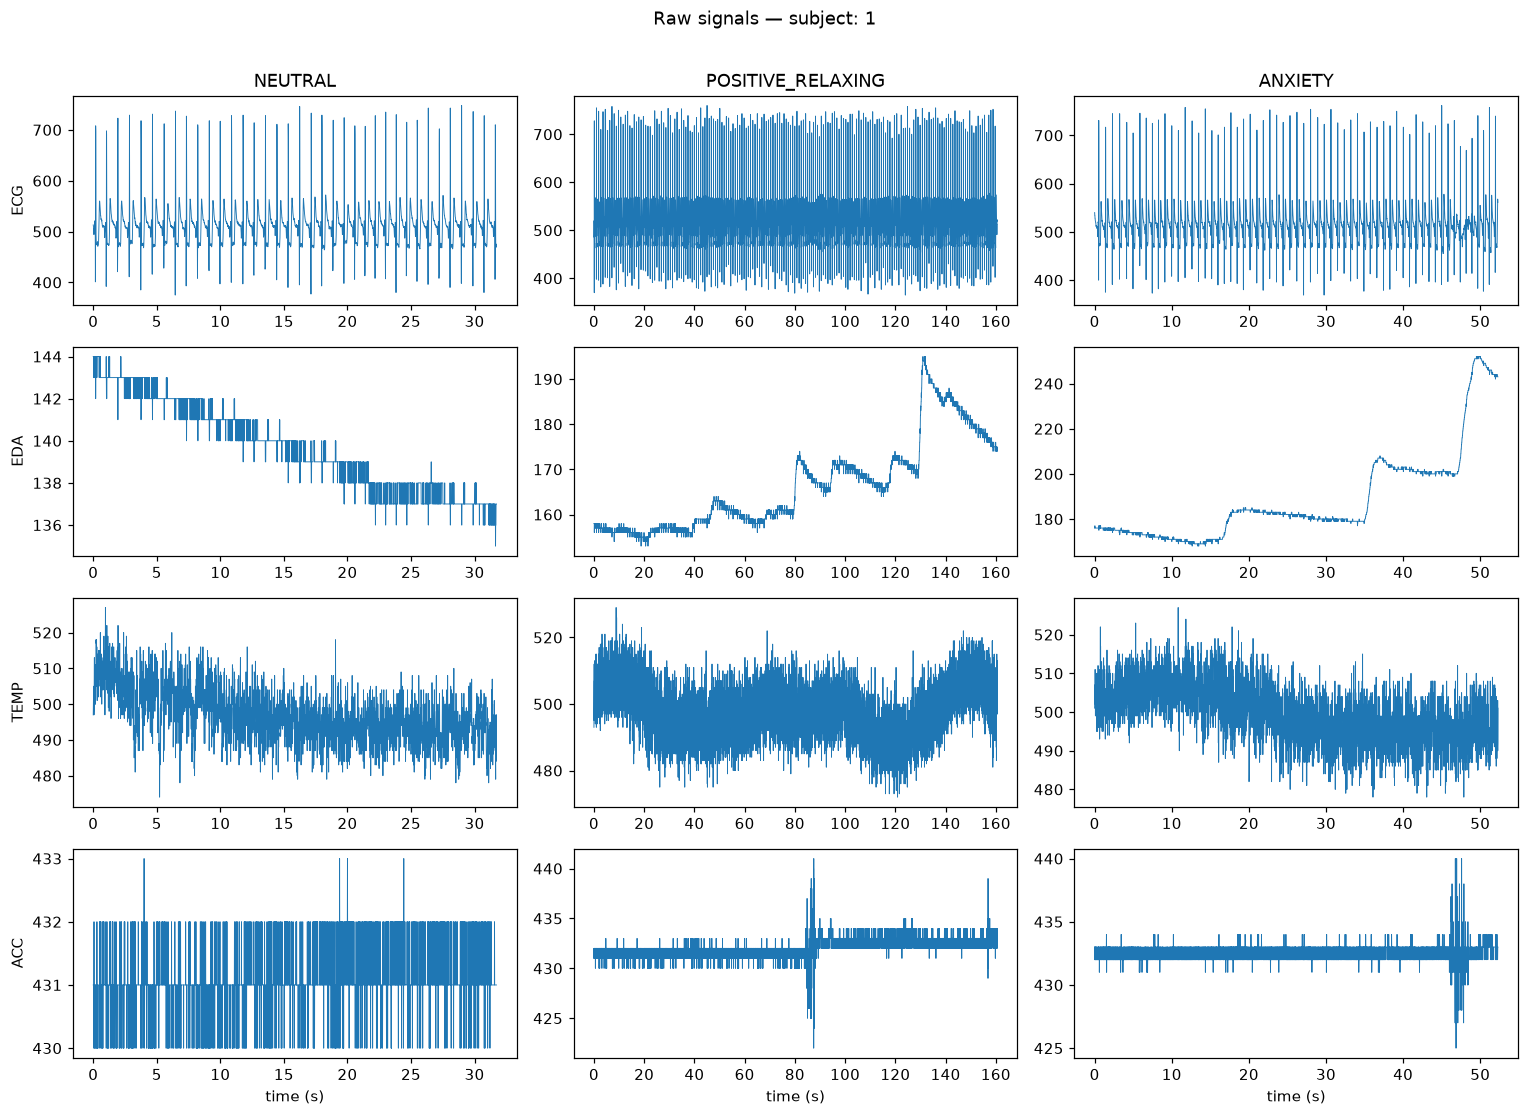

In [6]:

fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=False)
channels = ["ECG", "EDA", "TEMP", "ACC"]
for col, (cname, df) in enumerate(example_trials.items()):
    for row, ch in enumerate(channels):
        ax = axes[row, col]
        ax.plot(df["time_s"], df[ch], linewidth=0.6)
        if row == 0:
            ax.set_title(cname)
        if col == 0:
            ax.set_ylabel(ch)
        if row == 3:
            ax.set_xlabel("time (s)")
plt.suptitle(f"Raw signals — subject: {example_subject_dir.name}", y=1.01)
plt.tight_layout()
plt.show()


In [7]:

# Quick descriptive statistics per channel/class for the example subject
summary_rows = []
for cname, df in example_trials.items():
    for ch in channels:
        x = df[ch].to_numpy(float)
        summary_rows.append({"class": cname, "channel": ch,
                              "mean": np.mean(x), "std": np.std(x),
                              "min": np.min(x), "max": np.max(x)})
pd.DataFrame(summary_rows).pivot(index="channel", columns="class",
                                  values=["mean", "std"]).round(3)


mean                                std                          
class    ANXIETY  NEUTRAL POSITIVE_RELAXING ANXIETY NEUTRAL POSITIVE_RELAXING
channel                                                                      
ACC      432.477  431.076           432.040   0.737   0.520             0.967
ECG      511.380  511.432           511.421  41.536  40.293            41.689
EDA      188.760  139.649           166.475  20.590   2.141             9.959
TEMP     499.399  496.717           497.746   7.193   7.482             7.339


## 4. Preprocessing

Every trial goes through the same preprocessing before feature extraction:

1. **Edge trimming** (`EDGE_SEC` = 2 s from each side) — removes onset/offset
   transition artifacts (video start/stop, sensor settling).
2. **Missing-value interpolation** — linear interpolation over any NaNs.
3. **Band/low/high-pass Butterworth filtering**, channel-specific:
   - ECG: 0.5–40 Hz band-pass (removes baseline wander and high-freq noise)
   - EDA: 1 Hz low-pass (EDA is a slow signal)
   - TEMP: 0.5 Hz low-pass
   - ACC (quality/motion channel): 20 Hz low-pass
4. **Resampling** to a fixed target rate for EDA (16 Hz) and TEMP (4 Hz) so
   that windowed/segment features are computed on a uniform grid regardless
   of the original acquisition rate.

We visualize the effect of trimming + filtering on the EDA and ECG channels
for one example trial.


In [8]:

def crop_edges(df, edge_sec):
    if edge_sec <= 0 or len(df) < 3:
        return df.copy()
    t = df["time_s"].to_numpy(float)
    lo, hi = t[0] + edge_sec, t[-1] - edge_sec
    if hi <= lo:
        return df.copy()
    return df.loc[(df["time_s"] >= lo) & (df["time_s"] <= hi)].copy()


def interp_missing(x):
    x = np.asarray(x, dtype=float)
    good = np.isfinite(x)
    if good.sum() == 0 or np.all(good):
        return x
    idx = np.arange(len(x))
    return np.interp(idx, idx[good], x[good])


def butter_filter(x, fs, low=None, high=None, order=4):
    x = interp_missing(x)
    if len(x) < 20 or not np.isfinite(fs) or fs <= 0:
        return x
    try:
        if low is not None and high is not None:
            high = min(high, 0.45 * fs)
            if high <= low:
                return x
            sos = signal.butter(order, [low, high], btype="bandpass", fs=fs, output="sos")
        elif high is not None:
            sos = signal.butter(order, min(high, 0.45 * fs), btype="lowpass", fs=fs, output="sos")
        elif low is not None:
            sos = signal.butter(order, low, btype="highpass", fs=fs, output="sos")
        else:
            return x
        return signal.sosfiltfilt(sos, x)
    except Exception:
        return x


def resample_to(t, x, target_fs):
    t = np.asarray(t, float)
    x = interp_missing(x)
    fs = robust_fs(t)
    if not np.isfinite(fs) or fs <= target_fs * 1.1:
        return t, x
    ratio = Fraction(target_fs / fs).limit_denominator(1000)
    xr = signal.resample_poly(x, ratio.numerator, ratio.denominator)
    actual = fs * ratio.numerator / ratio.denominator
    return t[0] + np.arange(len(xr), dtype=float) / actual, xr


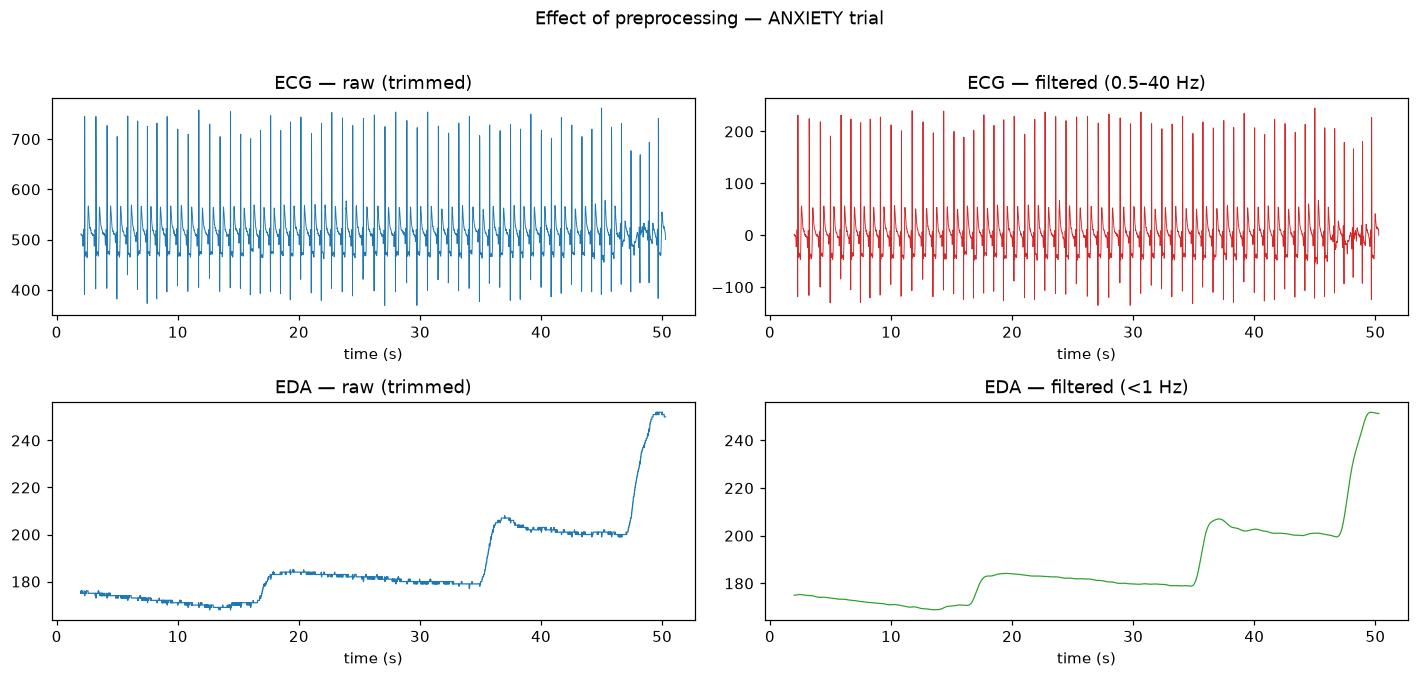

In [9]:

# Visualize preprocessing effect for the ANXIETY trial (ECG + EDA)
demo = crop_edges(example_trials["ANXIETY"], EDGE_SEC)
t = demo["time_s"].to_numpy(float)
fs = robust_fs(t)

ecg_raw = demo["ECG"].to_numpy(float)
ecg_f = butter_filter(signal.detrend(interp_missing(ecg_raw)), fs, low=0.5, high=40.0)

eda_raw = demo["EDA"].to_numpy(float)
eda_f = butter_filter(eda_raw, fs, high=1.0)

fig, axes = plt.subplots(2, 2, figsize=(13, 6))
axes[0, 0].plot(t, ecg_raw, linewidth=0.6); axes[0, 0].set_title("ECG — raw (trimmed)")
axes[0, 1].plot(t, ecg_f, linewidth=0.6, color="tab:red"); axes[0, 1].set_title("ECG — filtered (0.5–40 Hz)")
axes[1, 0].plot(t, eda_raw, linewidth=0.8); axes[1, 0].set_title("EDA — raw (trimmed)")
axes[1, 1].plot(t, eda_f, linewidth=0.8, color="tab:green"); axes[1, 1].set_title("EDA — filtered (<1 Hz)")
for ax in axes.ravel():
    ax.set_xlabel("time (s)")
plt.suptitle("Effect of preprocessing — ANXIETY trial", y=1.02)
plt.tight_layout()
plt.show()



## 5. EDA Tonic/Phasic Decomposition + SCR Events

EDA is decomposed into a slow **tonic** component (skin-conductance level,
estimated with a Savitzky–Golay smoother, ~4 s window) and a fast **phasic**
component (skin-conductance responses, SCRs). SCR peaks in the phasic
signal are detected with `scipy.signal.find_peaks` using an amplitude-
adaptive prominence threshold. SCR count/density/amplitude are strong
arousal markers and feed directly into the EDA feature set.


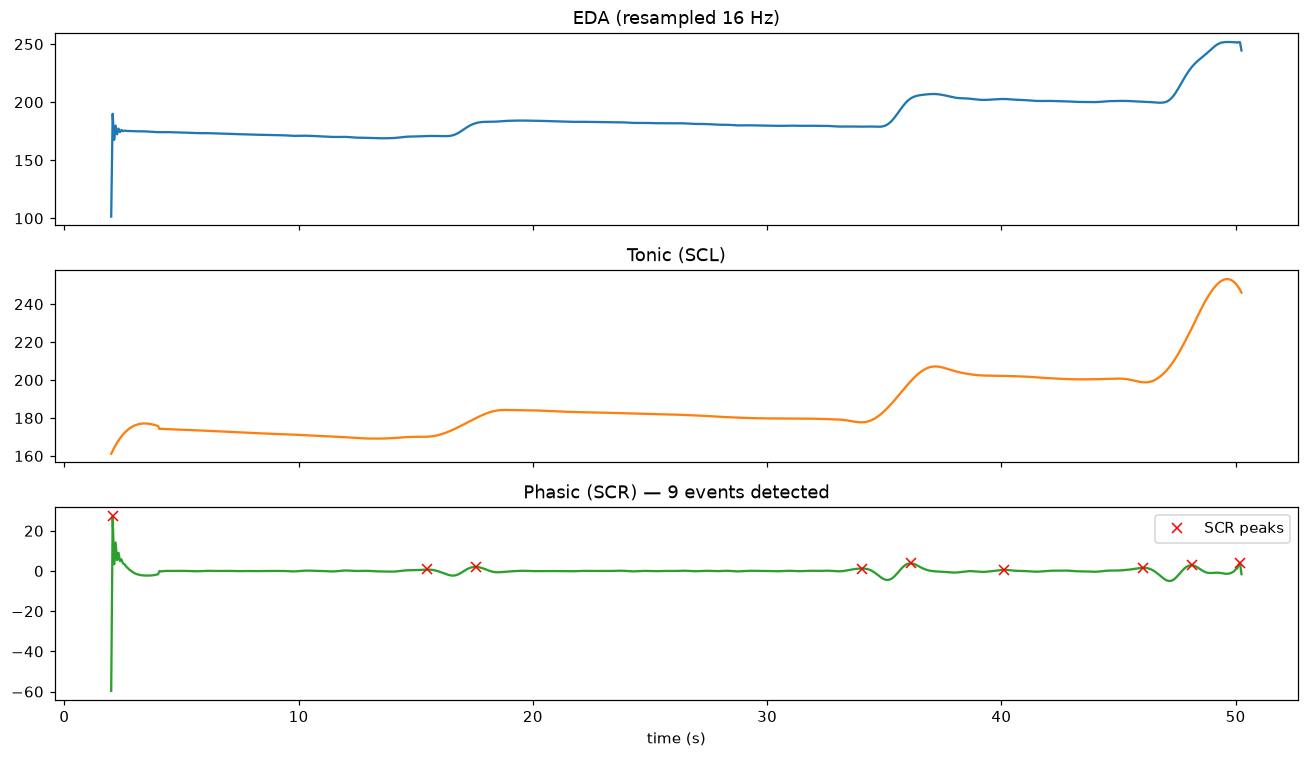

In [10]:

def tonic_phasic(x, fs):
    x = np.asarray(x, float)
    if len(x) < 7 or not np.isfinite(fs):
        tonic = np.full_like(x, np.nanmean(x))
        return tonic, x - tonic
    win = max(5, int(round(4.0 * fs)))
    if win % 2 == 0:
        win += 1
    if win >= len(x):
        win = len(x) if len(x) % 2 else len(x) - 1
    if win < 5:
        tonic = np.full_like(x, np.nanmean(x))
        return tonic, x - tonic
    try:
        tonic = signal.savgol_filter(x, window_length=win, polyorder=min(3, win - 2), mode="interp")
    except Exception:
        tonic = np.full_like(x, np.nanmean(x))
    return tonic, x - tonic


tr, xr = resample_to(t, eda_f, target_fs=16.0)
fsr = robust_fs(tr)
tonic, phasic = tonic_phasic(xr, fsr)

peaks, props = signal.find_peaks(phasic, distance=max(1, int(round(fsr))),
                                  prominence=max(0.01, 0.25 * float(np.std(phasic))))

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(tr, xr); axes[0].set_title("EDA (resampled 16 Hz)")
axes[1].plot(tr, tonic, color="tab:orange"); axes[1].set_title("Tonic (SCL)")
axes[2].plot(tr, phasic, color="tab:green"); axes[2].plot(tr[peaks], phasic[peaks], "rx", label="SCR peaks")
axes[2].set_title(f"Phasic (SCR) — {len(peaks)} events detected")
axes[2].legend()
axes[2].set_xlabel("time (s)")
plt.tight_layout()
plt.show()



## 6. ECG R-Peak Detection + Heart-Rate Variability (HRV)

R-peaks are detected with a Pan–Tompkins-style envelope: derivative →
square → moving-average envelope → `find_peaks` with a minimum refractory
distance (~0.30 s) and adaptive prominence. RR-intervals are cleaned
(physiological range 0.30–2.00 s, MAD-based outlier rejection) and turned
into time-domain (RMSSD, SDNN, pNN20/50) and frequency-domain (LF, HF,
LF/HF via Welch PSD of the interpolated tachogram) HRV features.


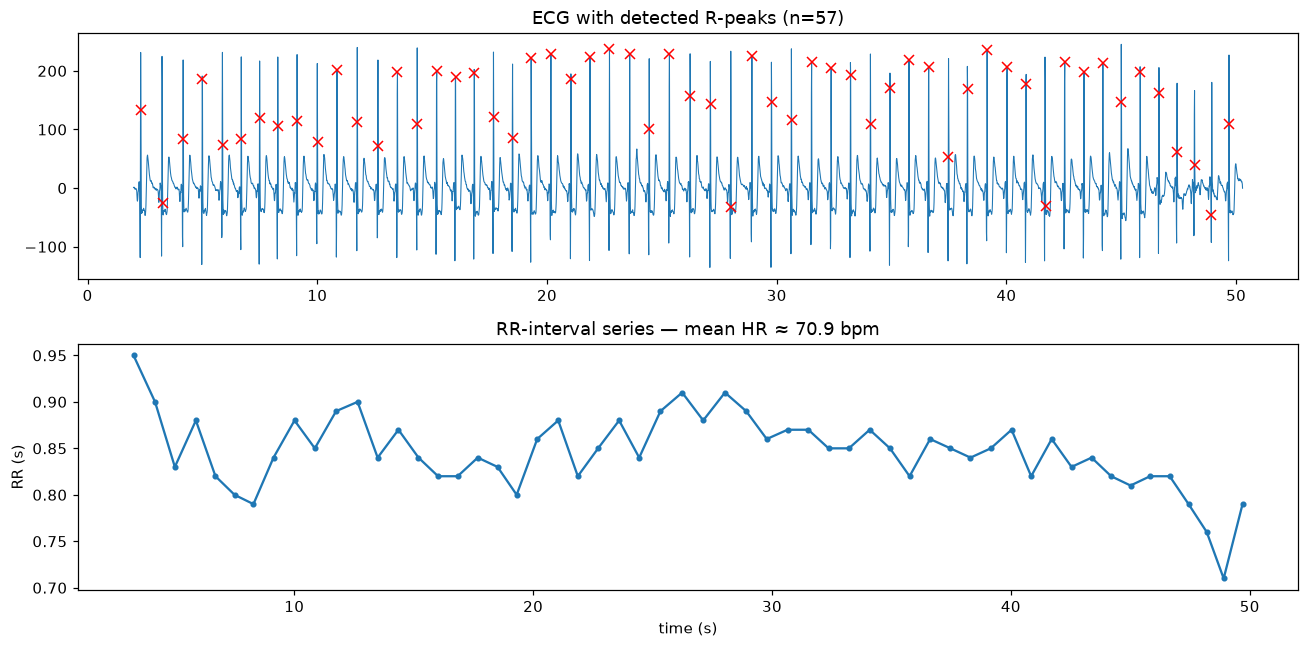

In [11]:

def detect_r_peaks(ecg_f, fs):
    if not np.isfinite(fs) or len(ecg_f) < int(max(5 * fs, 100)):
        return np.array([], dtype=int)
    derivative = np.diff(ecg_f, prepend=ecg_f[0])
    squared = derivative ** 2
    win = max(1, int(round(0.12 * fs)))
    envelope = np.convolve(squared, np.ones(win) / win, mode="same")
    peaks, _ = signal.find_peaks(envelope, distance=max(1, int(round(0.30 * fs))),
                                  prominence=max(1e-12, 0.35 * np.std(envelope)))
    return peaks


r_peaks = detect_r_peaks(ecg_f, fs)
rr = np.diff(t[r_peaks]) if len(r_peaks) >= 3 else np.array([])

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(t, ecg_f, linewidth=0.7)
axes[0].plot(t[r_peaks], ecg_f[r_peaks], "rx")
axes[0].set_title(f"ECG with detected R-peaks (n={len(r_peaks)})")
if len(rr):
    axes[1].plot(t[r_peaks][1:], rr, marker="o", markersize=3)
    axes[1].set_title(f"RR-interval series — mean HR ≈ {60/np.mean(rr):.1f} bpm")
    axes[1].set_ylabel("RR (s)")
axes[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()



## 7. Full Feature-Extraction Pipeline

Now we assemble the complete, validated feature extractor. For every
trial we compute, on the **whole** trimmed signal and (if long enough)
on its **early / middle / late thirds**:

- **ECG**: 13 generic statistics (mean, std, quantiles, RMS, slope,
  first-difference stats) on the filtered waveform + HRV time/frequency
  features + R-peak count.
- **EDA**: statistics on the raw/filtered signal, on the tonic component,
  on the phasic component, and SCR event features (count, density,
  amplitude, prominence, absolute area).
- **TEMP**: statistics + first/last and late/early deltas.
- **ACC** (motion-quality channel): statistics + mean absolute jerk.

Each segment (`whole`, `early`, `middle`, `late`) × modality contributes a
block of features, giving **456 raw features per trial** in total (before
any modality filtering). This matches the validated 456-feature reference
builder.


In [12]:

def safe_slope(t, x):
    t, x = np.asarray(t, float), np.asarray(x, float)
    m = np.isfinite(t) & np.isfinite(x)
    t, x = t[m], x[m]
    if len(x) < 3:
        return np.nan
    tc = t - t.mean()
    den = np.sum(tc * tc)
    return float(np.sum(tc * (x - x.mean())) / den) if den > 0 else np.nan


def basic_stats(t, x, prefix):
    t, x = np.asarray(t, float), np.asarray(x, float)
    m = np.isfinite(t) & np.isfinite(x)
    t, x = t[m], x[m]
    if len(x) == 0:
        return {}
    q25, q75 = np.percentile(x, [25, 75])
    out = {f"{prefix}_mean": float(np.mean(x)),
           f"{prefix}_std": float(np.std(x, ddof=1)) if len(x) > 1 else 0.0,
           f"{prefix}_median": float(np.median(x)),
           f"{prefix}_min": float(np.min(x)), f"{prefix}_max": float(np.max(x)),
           f"{prefix}_range": float(np.ptp(x)),
           f"{prefix}_q25": float(q25), f"{prefix}_q75": float(q75),
           f"{prefix}_iqr": float(q75 - q25),
           f"{prefix}_rms": float(np.sqrt(np.mean(x * x))),
           f"{prefix}_p05": float(np.percentile(x, 5)),
           f"{prefix}_p95": float(np.percentile(x, 95)),
           f"{prefix}_slope": safe_slope(t, x)}
    if len(x) > 1:
        d = np.diff(x)
        out[f"{prefix}_diff_abs_mean"] = float(np.mean(np.abs(d)))
        out[f"{prefix}_diff_std"] = float(np.std(d, ddof=1)) if len(d) > 1 else 0.0
    return out


In [13]:

def clean_rr(rr):
    rr = np.asarray(rr, float)
    rr = rr[np.isfinite(rr)]
    rr = rr[(rr >= 0.30) & (rr <= 2.00)]
    if len(rr) >= 4:
        med = np.median(rr)
        mad = np.median(np.abs(rr - med))
        if mad > 0:
            rr = rr[np.abs(rr - med) <= 4.5 * mad]
    return rr


def hrv_features(rr, prefix="hrv"):
    rr = clean_rr(rr)
    keys = ["n_rr", "hr_mean", "rr_mean", "rr_std", "rr_min", "rr_max",
            "rmssd", "sdnn", "pnn20", "pnn50", "lf", "hf", "lf_hf"]
    out = {f"{prefix}_{k}": np.nan for k in keys}
    out[f"{prefix}_n_rr"] = float(len(rr))
    if len(rr) < 2:
        return out
    d = np.diff(rr)
    out.update({f"{prefix}_hr_mean": float(60.0 / np.mean(rr)),
                f"{prefix}_rr_mean": float(np.mean(rr)),
                f"{prefix}_rr_std": float(np.std(rr, ddof=1)),
                f"{prefix}_rr_min": float(np.min(rr)),
                f"{prefix}_rr_max": float(np.max(rr)),
                f"{prefix}_rmssd": float(np.sqrt(np.mean(d ** 2))) if len(d) else np.nan,
                f"{prefix}_sdnn": float(np.std(rr, ddof=1)),
                f"{prefix}_pnn20": float(np.mean(np.abs(d) > 0.020)) if len(d) else np.nan,
                f"{prefix}_pnn50": float(np.mean(np.abs(d) > 0.050)) if len(d) else np.nan})
    if len(rr) >= 12 and np.sum(rr) >= 25:
        beat_t = np.cumsum(rr); beat_t -= beat_t[0]
        grid = np.arange(beat_t[0], beat_t[-1], 0.25)
        if len(grid) >= 32:
            tach = signal.detrend(np.interp(grid, beat_t, rr))
            f, pxx = signal.welch(tach, fs=4.0, nperseg=min(256, len(tach)))
            def bp(lo, hi):
                m = (f >= lo) & (f < hi)
                return float(trapezoid(pxx[m], f[m])) if m.sum() >= 2 else np.nan
            lf, hf = bp(0.04, 0.15), bp(0.15, 0.40)
            out[f"{prefix}_lf"], out[f"{prefix}_hf"] = lf, hf
            out[f"{prefix}_lf_hf"] = (float(lf / hf) if np.isfinite(lf) and np.isfinite(hf) and hf > 0 else np.nan)
    return out


def ecg_features(t, ecg, prefix="ecg"):
    fs = robust_fs(t)
    x = interp_missing(ecg)
    try:
        x = signal.detrend(x)
    except Exception:
        pass
    xf = butter_filter(x, fs, low=0.5, high=40.0, order=4)
    out = basic_stats(t, xf, prefix)
    peaks = detect_r_peaks(xf, fs)
    rr = np.diff(np.asarray(t)[peaks]) if len(peaks) >= 3 else np.array([])
    out.update(hrv_features(rr, prefix=f"{prefix}_hrv"))
    out[f"{prefix}_rpeak_count"] = float(len(peaks))
    return out


In [14]:

def eda_event_features(t, phasic, fs, prefix="eda_scr"):
    t, p = np.asarray(t, float), np.asarray(phasic, float)
    out = {f"{prefix}_count": 0.0, f"{prefix}_density": 0.0,
           f"{prefix}_amp_mean": 0.0, f"{prefix}_amp_max": 0.0,
           f"{prefix}_prom_mean": 0.0, f"{prefix}_prom_max": 0.0,
           f"{prefix}_abs_area": np.nan}
    if len(p) < 5:
        return out
    out[f"{prefix}_abs_area"] = float(trapezoid(np.abs(p), t))
    peaks, props = signal.find_peaks(p, distance=max(1, int(round(fs))) if np.isfinite(fs) else 1,
                                      prominence=max(0.01, 0.25 * float(np.std(p))))
    duration = max(float(t[-1] - t[0]), 1e-6)
    out[f"{prefix}_count"] = float(len(peaks))
    out[f"{prefix}_density"] = float(len(peaks) / duration)
    if len(peaks):
        amps = p[peaks]
        out[f"{prefix}_amp_mean"] = float(np.mean(amps))
        out[f"{prefix}_amp_max"] = float(np.max(amps))
        prom = props.get("prominences", np.array([]))
        prom = prom[np.isfinite(prom)]
        if len(prom):
            out[f"{prefix}_prom_mean"] = float(np.mean(prom))
            out[f"{prefix}_prom_max"] = float(np.max(prom))
    return out


def eda_features(t, eda, prefix="eda"):
    fs = robust_fs(t)
    xf = butter_filter(eda, fs, high=1.0, order=4)
    tr, xr = resample_to(t, xf, target_fs=16.0)
    fsr = robust_fs(tr)
    tonic, phasic = tonic_phasic(xr, fsr)
    out = {}
    out.update(basic_stats(tr, xr, prefix))
    out.update(basic_stats(tr, tonic, f"{prefix}_tonic"))
    out.update(basic_stats(tr, phasic, f"{prefix}_phasic"))
    out.update(eda_event_features(tr, phasic, fsr, f"{prefix}_scr"))
    return out


def temp_features(t, temp, prefix="temp"):
    fs = robust_fs(t)
    xf = butter_filter(temp, fs, high=0.5, order=3)
    tr, xr = resample_to(t, xf, target_fs=4.0)
    out = basic_stats(tr, xr, prefix)
    if len(xr) >= 2:
        out[f"{prefix}_first_last_delta"] = float(xr[-1] - xr[0])
        n = max(1, len(xr) // 10)
        out[f"{prefix}_late_early_delta"] = float(np.mean(xr[-n:]) - np.mean(xr[:n]))
    return out


def acc_quality_features(t, acc, prefix="accq"):
    fs = robust_fs(t)
    xf = butter_filter(acc, fs, high=20.0, order=3)
    out = basic_stats(t, xf, prefix)
    if len(xf) > 1:
        out[f"{prefix}_jerk_abs_mean"] = float(np.mean(np.abs(np.diff(xf))))
    return out


In [15]:

def extract_segment_features(seg, prefix):
    t = seg["time_s"].to_numpy(float)
    out = {}
    out.update(ecg_features(t, pd.to_numeric(seg["ECG"], errors="coerce").to_numpy(float), f"{prefix}_ecg"))
    out.update(eda_features(t, pd.to_numeric(seg["EDA"], errors="coerce").to_numpy(float), f"{prefix}_eda"))
    out.update(temp_features(t, pd.to_numeric(seg["TEMP"], errors="coerce").to_numpy(float), f"{prefix}_temp"))
    out.update(acc_quality_features(t, pd.to_numeric(seg["ACC"], errors="coerce").to_numpy(float), f"{prefix}_accq"))
    return out


def extract_trial_features(df, edge_sec=2.0, temporal_thirds=True):
    df = crop_edges(df, edge_sec=edge_sec)
    if len(df) < 100:
        return {}
    out = {}
    out.update(extract_segment_features(df, "whole"))
    if temporal_thirds:
        t = df["time_s"].to_numpy(float)
        lo, hi = float(t[0]), float(t[-1])
        dur = hi - lo
        if dur > 9:
            c1, c2 = lo + dur / 3.0, lo + 2.0 * dur / 3.0
            thirds = {"early": df.loc[(df["time_s"] >= lo) & (df["time_s"] < c1)],
                      "middle": df.loc[(df["time_s"] >= c1) & (df["time_s"] < c2)],
                      "late": df.loc[(df["time_s"] >= c2) & (df["time_s"] <= hi)]}
            for name, seg in thirds.items():
                if len(seg) >= 50:
                    out.update(extract_segment_features(seg, name))
    return out


In [16]:

# Sanity check on the example ANXIETY trial
demo_features = extract_trial_features(example_trials["ANXIETY"], EDGE_SEC, TEMPORAL_THIRDS)
print(f"Extracted {len(demo_features)} features for one trial")
list(demo_features.items())[:10]


Extracted 456 features for one trial


[('whole_ecg_mean', 0.0020322650718541425),
 ('whole_ecg_std', 41.15688265942826),
 ('whole_ecg_median', -0.314523278828271),
 ('whole_ecg_min', -135.3306614241861),
 ('whole_ecg_max', 245.27998097010874),
 ('whole_ecg_range', 380.6106423942948),
 ('whole_ecg_q25', -25.381126583114835),
 ('whole_ecg_q75', 11.415614475949372),
 ('whole_ecg_iqr', 36.7967410590642),
 ('whole_ecg_rms', 41.152621059826544)]


## 8. Dataset Construction (all participants)

We now run the extractor over every participant folder and every target
video (1, 3, 5), producing one row per (subject, video) with 456 raw
features plus metadata (`subject`, `video_id`, `class_name`, `label`,
`duration_s`). This is the **reference 456-feature builder**.

⚠️ This cell processes every subject's raw signal files and can take a
few minutes depending on dataset size.


In [17]:

def build_dataset(root, video_to_class, edge_sec, temporal_thirds):
    participants = find_participant_dirs(root, list(video_to_class))
    rows, failures = [], []
    for p in participants:
        subject = p.name
        for vid, (label, cname) in video_to_class.items():
            path = p / f"bitalino_{vid}.txt"
            if not path.exists():
                failures.append((subject, vid, "missing file"))
                continue
            try:
                df = read_bitalino_txt(path)
                duration = float(df["time_s"].iloc[-1] - df["time_s"].iloc[0])
                feats = extract_trial_features(df, edge_sec, temporal_thirds)
                if not feats:
                    failures.append((subject, vid, "no features"))
                    continue
                row = {"subject": subject, "video_id": vid, "class_name": cname,
                       "label": label, "duration_s": duration}
                row.update(feats)
                rows.append(row)
            except Exception as exc:
                failures.append((subject, vid, str(exc)[:80]))
    return pd.DataFrame(rows), failures


raw_data, failures = build_dataset(DATASET_ROOT, VIDEO_TO_CLASS, EDGE_SEC, TEMPORAL_THIRDS)
print(f"Samples = {len(raw_data)} | Subjects = {raw_data['subject'].nunique()} | "
      f"Raw feature columns = {raw_data.shape[1] - 5}")
if failures:
    print(f"\nFailures: {len(failures)} (first 5 shown)")
    for f in failures[:5]:
        print(" ", f)


Samples = 129 | Subjects = 43 | Raw feature columns = 456

Failures: 3 (first 5 shown)
  ('27', 1, 'No numeric BITalino rows parsed from D:\\rohullah\\EmoWear2\\Physiological Response')
  ('27', 3, 'No numeric BITalino rows parsed from D:\\rohullah\\EmoWear2\\Physiological Response')
  ('27', 5, 'No numeric BITalino rows parsed from D:\\rohullah\\EmoWear2\\Physiological Response')



## 9. Keep Only Subjects with All Three Trials

For a fair, balanced three-class problem we keep only subjects who have
usable recordings for **all three** target videos (1, 3, 5).


In [18]:

def keep_complete_subjects(data, required_videos):
    counts = data.groupby("subject")["video_id"].nunique()
    complete = set(counts[counts == len(required_videos)].index)
    return data[data["subject"].isin(complete)].reset_index(drop=True)


data = keep_complete_subjects(raw_data, set(VIDEO_TO_CLASS))
print(f"Samples = {len(data)} | Subjects = {data['subject'].nunique()}")
print("\nClass distribution:")
print(data["class_name"].value_counts().sort_index().to_string())

recording_counts = data.groupby("subject").size()
print(f"\nRecordings per subject: min={recording_counts.min()}, "
      f"max={recording_counts.max()}, mean={recording_counts.mean():.2f}")


Samples = 129 | Subjects = 43

Class distribution:
class_name
ANXIETY              43
NEUTRAL              43
POSITIVE_RELAXING    43

Recordings per subject: min=3, max=3, mean=3.00



## 10. Modality-Aware Feature Selection (ECG + EDA only)

The 456 raw features span ECG, EDA, TEMP and ACC. For the ECG+EDA
protocol we keep only columns whose name matches an ECG or EDA pattern
(case-insensitive substring match), dropping TEMP/ACC-derived columns.
This reproduces the paper's reported **116 ECG + 208 EDA = 324 combined
features**.


In [19]:

META_COLUMNS = {"subject", "video_id", "class_name", "label", "duration_s"}

def _match_any_pattern(column_name, patterns):
    lowered = str(column_name).lower()
    return any(p and p.lower() in lowered for p in patterns)


def select_modality_features(data, ecg_patterns, eda_patterns):
    all_features = [c for c in data.columns if c not in META_COLUMNS]
    ecg_features, eda_features = [], []
    for c in all_features:
        is_ecg = _match_any_pattern(c, ecg_patterns)
        is_eda = _match_any_pattern(c, eda_patterns)
        if is_ecg:
            ecg_features.append(c)
        elif is_eda:
            eda_features.append(c)
    return ecg_features, eda_features


def build_combined_feature_list(ecg_features, eda_features):
    combined = list(ecg_features) + list(eda_features)
    seen, unique = set(), []
    for c in combined:
        if c not in seen:
            unique.append(c); seen.add(c)
    return unique


ecg_feature_cols, eda_feature_cols = select_modality_features(data, ECG_PATTERNS, EDA_PATTERNS)
feature_columns = build_combined_feature_list(ecg_feature_cols, eda_feature_cols)

print(f"ECG features selected : {len(ecg_feature_cols)}")
print(f"EDA features selected : {len(eda_feature_cols)}")
print(f"Combined features     : {len(feature_columns)}")


ECG features selected : 116
EDA features selected : 208
Combined features     : 324



## 11. Exploratory Analysis of the Feature Table

Before modeling, we look at the ECG+EDA feature table itself:

- Basic `describe()` summary
- Class-wise distributions for a few representative features (heart rate,
  SCR count/amplitude)
- A correlation heatmap (top-variance features) to check redundancy
- A PCA projection colored by **class** and, separately, by **subject**,
  to visually confirm the inter-subject baseline-offset problem that
  motivates per-subject normalization (step 12).


In [20]:

X_raw = data[feature_columns].apply(pd.to_numeric, errors="coerce")
X_raw.describe().T[["mean", "std", "min", "max"]].head(10)


,mean,std,min,max
whole_ecg_mean,0.014051,0.162185,-0.621661,1.054247
whole_ecg_std,36.494374,25.420866,0.382950,126.079468
whole_ecg_median,-0.799862,2.582920,-22.204615,2.374956
whole_ecg_min,-176.903575,161.307019,-913.330680,-1.385923
whole_ecg_max,189.336390,169.095567,1.327988,1016.562530
whole_ecg_range,366.239965,282.830204,2.805531,1635.929702
whole_ecg_q25,-10.965699,9.970288,-42.610815,-0.164034
whole_ecg_q75,9.910907,9.982389,-3.560608,51.656861
whole_ecg_iqr,20.876606,17.184520,0.418595,93.667053
whole_ecg_rms,36.491763,25.419144,0.382938,126.075520


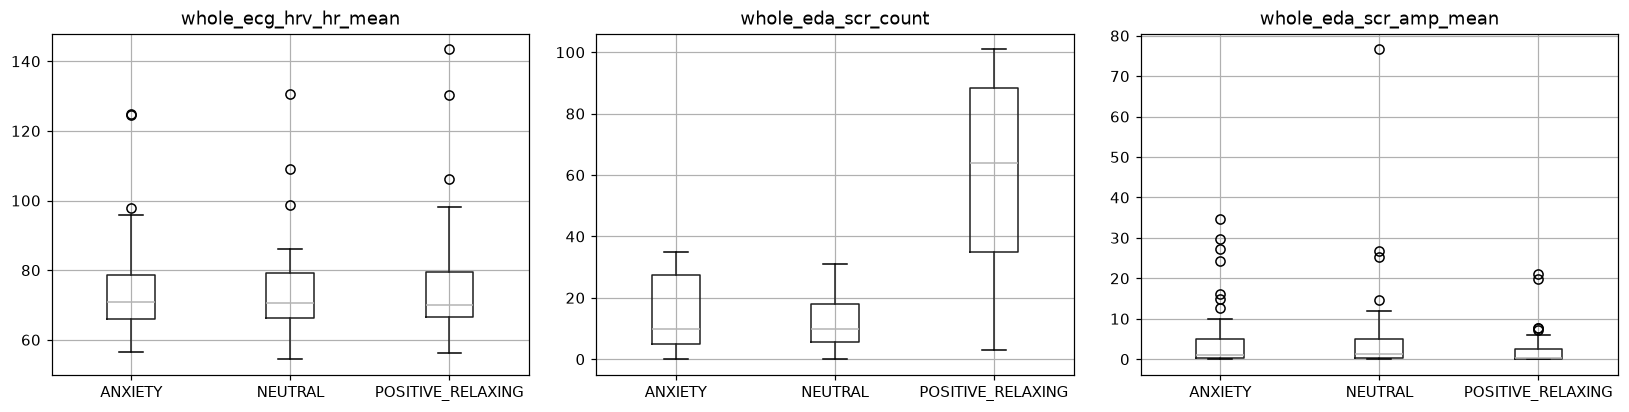

In [21]:

example_feats = [c for c in ["whole_ecg_hrv_hr_mean", "whole_eda_scr_count",
                              "whole_eda_scr_amp_mean"] if c in X_raw.columns]
fig, axes = plt.subplots(1, len(example_feats), figsize=(5 * len(example_feats), 4))
if len(example_feats) == 1:
    axes = [axes]
for ax, feat in zip(axes, example_feats):
    plot_df = pd.DataFrame({feat: X_raw[feat], "class": data["class_name"]})
    plot_df.boxplot(column=feat, by="class", ax=ax)
    ax.set_title(feat)
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()


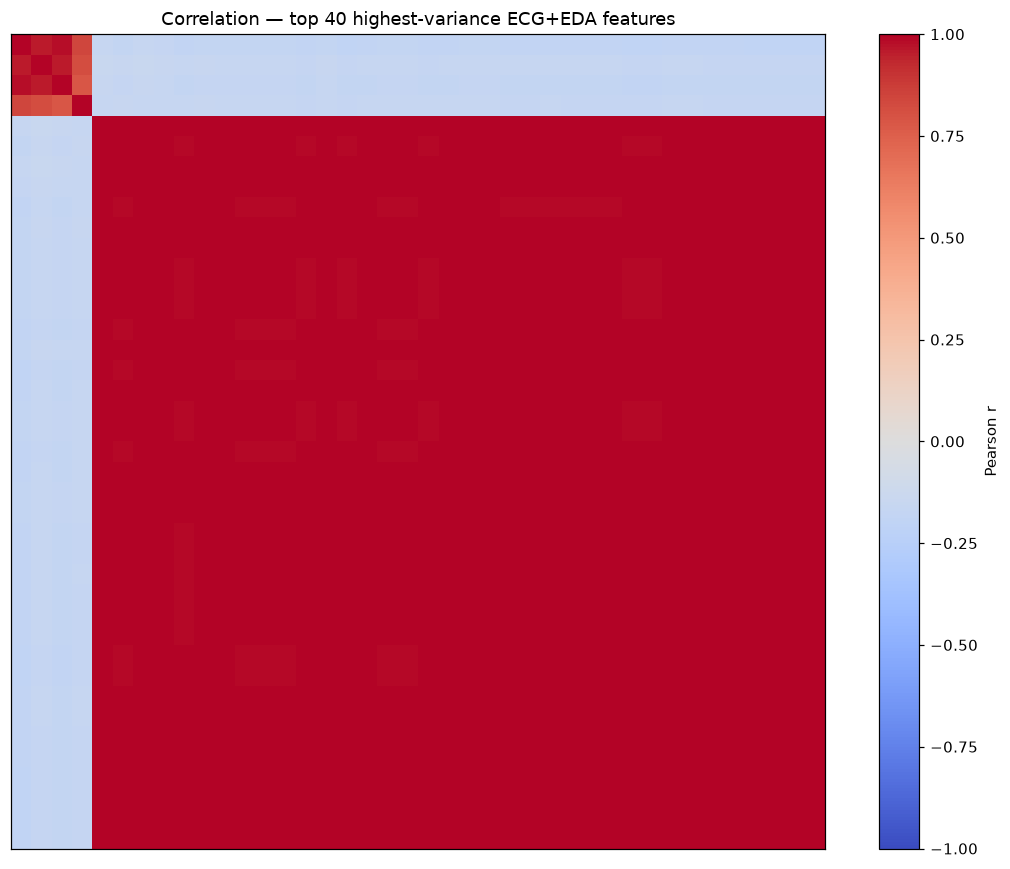

In [22]:

# Correlation heatmap of the top-variance ECG+EDA features
top_var_cols = X_raw.var().sort_values(ascending=False).head(40).index
corr = X_raw[top_var_cols].fillna(X_raw[top_var_cols].median()).corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson r")
plt.title("Correlation — top 40 highest-variance ECG+EDA features")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()


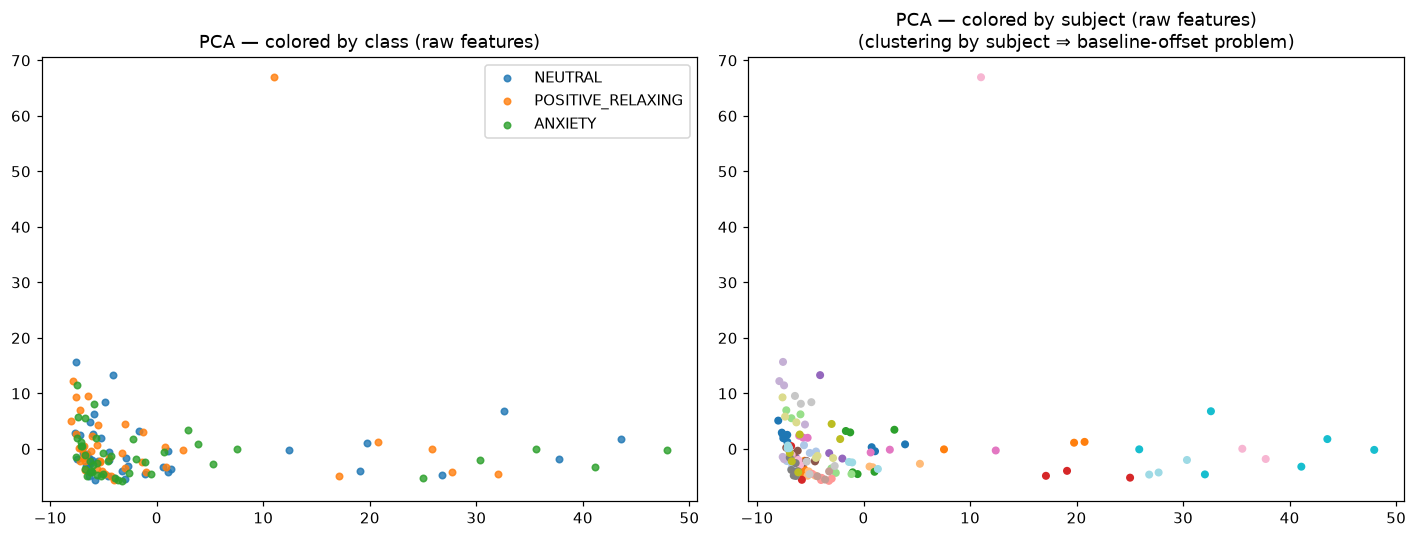

In [23]:

# PCA: colored by class vs. colored by subject (raw, before subject normalization)
X_imputed = SimpleImputer(strategy="median").fit_transform(X_raw)
X_scaled = StandardScaler().fit_transform(X_imputed)
pcs = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for cls in CLASS_NAMES:
    m = data["class_name"].to_numpy() == cls
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=18, label=cls, alpha=0.8)
axes[0].set_title("PCA — colored by class (raw features)")
axes[0].legend()

subj_codes = data["subject"].astype("category").cat.codes
sc = axes[1].scatter(pcs[:, 0], pcs[:, 1], c=subj_codes, cmap="tab20", s=18)
axes[1].set_title("PCA — colored by subject (raw features)\n(clustering by subject ⇒ baseline-offset problem)")
plt.tight_layout()
plt.show()



## 12. Per-Subject Normalization

Different subjects have different resting EDA/HR baselines. If left
uncorrected, a classifier can partly learn *who the subject is* rather
than *what emotional state they are in* — and confounds NEUTRAL vs.
ANXIETY, whose autonomic signatures otherwise overlap.

`apply_subject_norm` removes each subject's own mean (`center`) or
z-scores each subject's own features (`zscore`), using **only that
subject's own samples** — no label information is used, so this does not
leak test-set information across the subject-disjoint CV splits (each
subject's samples still only ever land in one CV fold's train or test set
per split, and normalization uses only within-subject statistics).


In [24]:

def apply_subject_norm(df, feat_cols, mode):
    if mode == "none":
        return df.copy()
    out = df.copy()
    g = out.groupby("subject")[feat_cols]
    mu = g.transform("mean")
    if mode == "center":
        out[feat_cols] = out[feat_cols] - mu
    elif mode == "zscore":
        sd = g.transform("std").replace(0, np.nan)
        out[feat_cols] = (out[feat_cols] - mu) / sd
    return out


# Make sure feature columns are numeric before normalizing
data[feature_columns] = data[feature_columns].apply(pd.to_numeric, errors="coerce")
data_norm = apply_subject_norm(data, feature_columns, SUBJECT_NORM)
print(f"Subject normalization applied: '{SUBJECT_NORM}'")


Subject normalization applied: 'zscore'


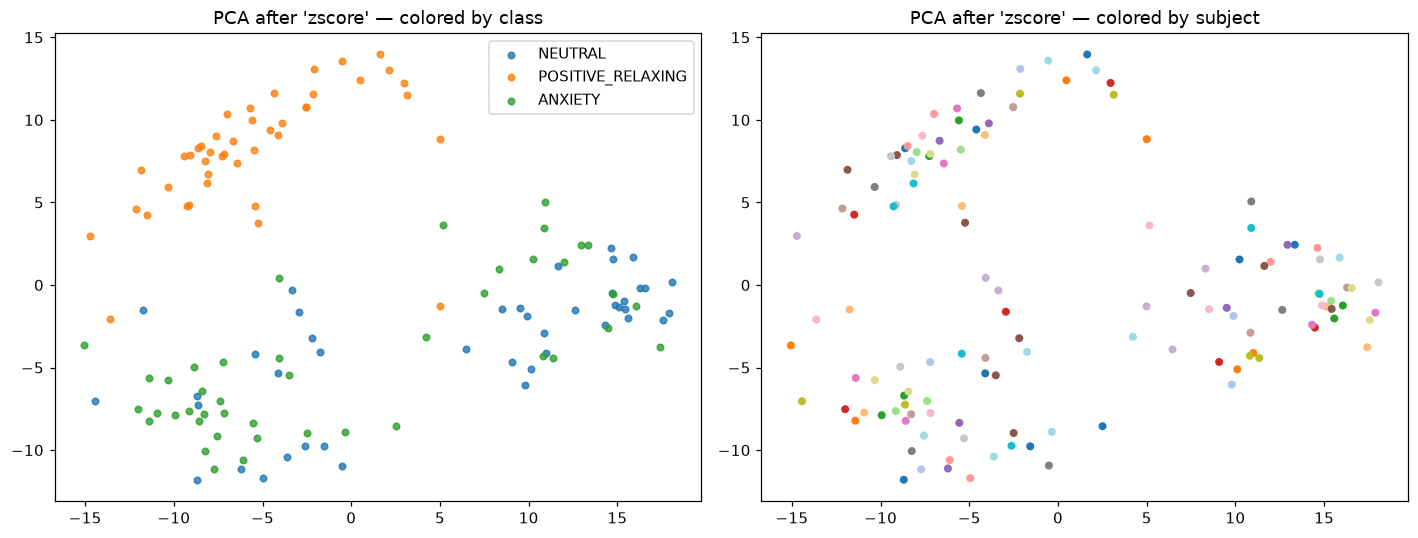

In [25]:

# Re-check PCA after normalization — subject clusters should be less pronounced
X_norm = data_norm[feature_columns].replace([np.inf, -np.inf], np.nan)
X_norm_imputed = SimpleImputer(strategy="median").fit_transform(X_norm)
X_norm_scaled = StandardScaler().fit_transform(X_norm_imputed)
pcs_norm = PCA(n_components=2, random_state=SEED).fit_transform(X_norm_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for cls in CLASS_NAMES:
    m = data_norm["class_name"].to_numpy() == cls
    axes[0].scatter(pcs_norm[m, 0], pcs_norm[m, 1], s=18, label=cls, alpha=0.8)
axes[0].set_title(f"PCA after '{SUBJECT_NORM}' — colored by class")
axes[0].legend()

sc = axes[1].scatter(pcs_norm[:, 0], pcs_norm[:, 1], c=subj_codes, cmap="tab20", s=18)
axes[1].set_title(f"PCA after '{SUBJECT_NORM}' — colored by subject")
plt.tight_layout()
plt.show()



## 13. Model Definitions

Five gradient-boosting / tabular models are benchmarked, matching the
paper's model list. Each is wrapped so that missing packages are skipped
gracefully with a warning rather than crashing the notebook.

- **CatBoost** — ordered boosting, strong on small/medium tabular data
- **TabPFN** — prior-fitted transformer (requires a one-time online
  license acceptance; skip if you don't want the browser/API-key flow)
- **LightGBM** — leaf-wise gradient boosting
- **XGBoost** — histogram-based gradient boosting
- **HistGradientBoosting** — scikit-learn's built-in histogram GBDT (no
  extra dependency; always available)


In [37]:

SKIP_TABPFN = False  # TabPFN is included in every requested benchmark

def build_models(seed):
    models = {}

    try:
        from catboost import CatBoostClassifier
        models["CatBoost"] = CatBoostClassifier(
            iterations=500, depth=5, learning_rate=0.03,
            loss_function="MultiClass", eval_metric="MultiClass",
            random_seed=seed, verbose=False, allow_writing_files=False,
            l2_leaf_reg=5, thread_count=-1)
    except ImportError:
        print("[WARNING] CatBoost not installed — pip install catboost")

    try:
        from tabpfn import TabPFNClassifier
        try:
            models["TabPFN"] = TabPFNClassifier(device="cpu", random_state=seed)
        except TypeError:
            models["TabPFN"] = TabPFNClassifier(device="cpu")
    except ImportError:
        print("[WARNING] TabPFN not installed — pip install tabpfn")

    try:
        from lightgbm import LGBMClassifier
        models["LightGBM"] = LGBMClassifier(
            n_estimators=500, learning_rate=0.03, num_leaves=15, max_depth=-1,
            min_child_samples=8, subsample=0.85, colsample_bytree=0.85,
            reg_lambda=1.0, objective="multiclass", random_state=seed,
            n_jobs=-1, verbosity=-1)
    except ImportError:
        print("[WARNING] LightGBM not installed — pip install lightgbm")

    try:
        from xgboost import XGBClassifier
        models["XGBoost"] = XGBClassifier(
            n_estimators=500, max_depth=3, learning_rate=0.03, min_child_weight=2,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            objective="multi:softprob", eval_metric="mlogloss", num_class=3,
            random_state=seed, n_jobs=-1, tree_method="hist")
    except ImportError:
        print("[WARNING] XGBoost not installed — pip install xgboost")

    models["HistGradientBoosting"] = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=seed)

    return models

models_preview = build_models(SEED)
print("Models available:", list(models_preview.keys()))


Models available: ['CatBoost', 'TabPFN', 'LightGBM', 'XGBoost', 'HistGradientBoosting']



## 14. Subject-Disjoint Repeated Cross-Validation

We use `StratifiedGroupKFold` with `groups = subject`, so **no participant
ever contributes samples to both the train and test side of a fold** — this
is the subject-independent evaluation the paper argues is necessary
(subject-dependent splits inflate accuracy). The whole split is repeated
`REPEATS` times with different random seeds and results are pooled/averaged
(`FOLDS` × `REPEATS` evaluations per model), which also gives a much more
stable estimate than a single 10-fold run.

Only the `SimpleImputer` is inside the CV loop (fit on the training fold
only) since feature selection (ECG/EDA) and subject normalization are both
label-free and computed from each subject's own data — but we still keep
the imputer in-fold for cleanliness.


In [27]:

def flatten_predictions(predictions):
    values = np.asarray(predictions).reshape(-1)
    name_to_label = {"NEUTRAL": 0, "POSITIVE": 1, "POSITIVE_RELAXING": 1,
                      "RELAXING": 1, "ANXIETY": 2, "NEGATIVE": 2}
    output = []
    for value in values:
        if isinstance(value, np.generic):
            value = value.item()
        try:
            iv = int(value)
            if iv in (0, 1, 2):
                output.append(iv)
                continue
        except (TypeError, ValueError):
            pass
        text = str(value).strip().upper()
        if text not in name_to_label:
            raise ValueError(f"Unknown predicted label: {value}")
        output.append(name_to_label[text])
    return np.asarray(output, dtype=int)


def evaluate_model(model_name, model, X, y, groups, folds, repeats, seed, verbose=True):
    labels = [0, 1, 2]
    fold_results = []
    pooled_cm = np.zeros((3, 3), dtype=int)
    total = folds * repeats
    completed = 0

    for repeat in range(repeats):
        splitter = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed + repeat)
        for fold, (train_idx, test_idx) in enumerate(splitter.split(X, y, groups), start=1):
            completed += 1
            pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("model", clone(model)),
            ])
            pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])
            preds = flatten_predictions(pipeline.predict(X.iloc[test_idx]))
            y_test = y.iloc[test_idx]

            acc = accuracy_score(y_test, preds)
            bacc = balanced_accuracy_score(y_test, preds)
            f1m = f1_score(y_test, preds, average="macro", zero_division=0)
            pooled_cm += confusion_matrix(y_test, preds, labels=labels)

            fold_results.append({"repeat": repeat + 1, "fold": fold,
                                  "accuracy": acc, "balanced_accuracy": bacc, "macro_f1": f1m})
            if verbose:
                print(f"  [{completed}/{total}] Repeat {repeat+1}, Fold {fold}... "
                      f"Acc={acc*100:.2f}% | BalAcc={bacc*100:.2f}% | F1={f1m*100:.2f}%")

    res = pd.DataFrame(fold_results)
    return {
        "accuracy_mean": res["accuracy"].mean(), "accuracy_std": res["accuracy"].std(ddof=1),
        "balanced_accuracy_mean": res["balanced_accuracy"].mean(),
        "balanced_accuracy_std": res["balanced_accuracy"].std(ddof=1),
        "macro_f1_mean": res["macro_f1"].mean(), "macro_f1_std": res["macro_f1"].std(ddof=1),
        "confusion_matrix": pooled_cm,
    }


In [28]:

# Final X / y / groups for modeling
X = data_norm[feature_columns].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).reset_index(drop=True)
y = data_norm["label"].astype(int).reset_index(drop=True)
groups = data_norm["subject"].astype(str).reset_index(drop=True)

print(f"X = {X.shape[0]} samples x {X.shape[1]} features (ECG+EDA)")
print(f"y classes = {sorted(y.unique().tolist())}")
print(f"groups = {groups.nunique()} subjects")
assert X.shape[1] > 0 and y.nunique() == 3, "Safety check failed."


X = 129 samples x 324 features (ECG+EDA)
y classes = [0, 1, 2]
groups = 43 subjects



## 15. Run the Benchmark

Loops over every available model and evaluates it with the subject-disjoint
repeated CV protocol above. TabPFN is skipped by default (`SKIP_TABPFN =
True` in the model-definitions cell) since it needs a one-time online
license/auth step; set it to `False` if you want to include it.


In [29]:

models = build_models(SEED)
if SKIP_TABPFN:
    models.pop("TabPFN", None)

summaries = []
confusion_matrices = {}

for i, (name, model) in enumerate(models.items(), start=1):
    print("=" * 60)
    print(f"MODEL {i}/{len(models)}: {name}")
    print("=" * 60)
    try:
        summary = evaluate_model(name, model, X, y, groups, FOLDS, REPEATS, SEED)
    except Exception as exc:
        print(f"[WARNING] {name} failed and was skipped: {exc}")
        continue

    confusion_matrices[name] = summary["confusion_matrix"]
    summaries.append({
        "Model": name,
        "Accuracy": summary["accuracy_mean"] * 100,
        "Accuracy Std": summary["accuracy_std"] * 100,
        "Balanced Accuracy": summary["balanced_accuracy_mean"] * 100,
        "Balanced Accuracy Std": summary["balanced_accuracy_std"] * 100,
        "Macro-F1": summary["macro_f1_mean"] * 100,
        "Macro-F1 Std": summary["macro_f1_std"] * 100,
    })
    print(f"\nAccuracy: {summary['accuracy_mean']*100:.2f}% ± {summary['accuracy_std']*100:.2f}%")
    print(f"Balanced Accuracy: {summary['balanced_accuracy_mean']*100:.2f}% ± {summary['balanced_accuracy_std']*100:.2f}%")
    print(f"Macro-F1: {summary['macro_f1_mean']*100:.2f}% ± {summary['macro_f1_std']*100:.2f}%\n")


MODEL 1/4: CatBoost
  [1/25] Repeat 1, Fold 1... Acc=92.59% | BalAcc=92.59% | F1=92.59%
  [2/25] Repeat 1, Fold 2... Acc=92.59% | BalAcc=92.59% | F1=92.59%
  [3/25] Repeat 1, Fold 3... Acc=85.19% | BalAcc=85.19% | F1=85.19%
  [4/25] Repeat 1, Fold 4... Acc=83.33% | BalAcc=83.33% | F1=83.56%
  [5/25] Repeat 1, Fold 5... Acc=83.33% | BalAcc=83.33% | F1=83.33%
  [6/25] Repeat 2, Fold 1... Acc=77.78% | BalAcc=77.78% | F1=77.78%
  [7/25] Repeat 2, Fold 2... Acc=85.19% | BalAcc=85.19% | F1=85.19%
  [8/25] Repeat 2, Fold 3... Acc=96.30% | BalAcc=96.30% | F1=96.28%
  [9/25] Repeat 2, Fold 4... Acc=95.83% | BalAcc=95.83% | F1=95.82%
  [10/25] Repeat 2, Fold 5... Acc=91.67% | BalAcc=91.67% | F1=91.65%
  [11/25] Repeat 3, Fold 1... Acc=81.48% | BalAcc=81.48% | F1=81.57%
  [12/25] Repeat 3, Fold 2... Acc=100.00% | BalAcc=100.00% | F1=100.00%
  [13/25] Repeat 3, Fold 3... Acc=92.59% | BalAcc=92.59% | F1=92.59%
  [14/25] Repeat 3, Fold 4... Acc=83.33% | BalAcc=83.33% | F1=83.33%
  [15/25] Repeat 3, 


## 16. Results

Final leaderboard, pooled confusion matrices (all held-out predictions
across folds/repeats), and per-class accuracy.


In [30]:

result_table = (pd.DataFrame(summaries)
                 .sort_values(["Balanced Accuracy", "Macro-F1", "Accuracy"], ascending=False)
                 .reset_index(drop=True))
result_table.style.format({c: "{:.2f}%" for c in result_table.columns if c != "Model"})


,Model,Accuracy,Accuracy Std,Balanced Accuracy,Balanced Accuracy Std,Macro-F1,Macro-F1 Std
0,XGBoost,88.44%,7.65%,88.44%,7.65%,88.50%,7.51%
1,CatBoost,88.19%,5.38%,88.19%,5.38%,88.19%,5.35%
2,LightGBM,87.50%,6.37%,87.50%,6.37%,87.49%,6.40%
3,HistGradientBoosting,87.20%,6.18%,87.20%,6.18%,87.15%,6.22%


In [31]:

best_model_name = result_table.iloc[0]["Model"]
cm = confusion_matrices[best_model_name]
cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)

print(f"Best model: {best_model_name}")
print("\nPooled confusion matrix (rows = true, columns = predicted):")
print(cm_df.to_string())

print("\nPer-class pooled accuracy:")
for i, cls in enumerate(CLASS_NAMES):
    total, correct = int(cm[i].sum()), int(cm[i, i])
    pct = 100.0 * correct / total if total else 0.0
    print(f"  {cls}: {correct}/{total} = {pct:.2f}%")


Best model: XGBoost

Pooled confusion matrix (rows = true, columns = predicted):
                   NEUTRAL  POSITIVE_RELAXING  ANXIETY
NEUTRAL                181                  1       33
POSITIVE_RELAXING        5                208        2
ANXIETY                 33                  0      182

Per-class pooled accuracy:
  NEUTRAL: 181/215 = 84.19%
  POSITIVE_RELAXING: 208/215 = 96.74%
  ANXIETY: 182/215 = 84.65%


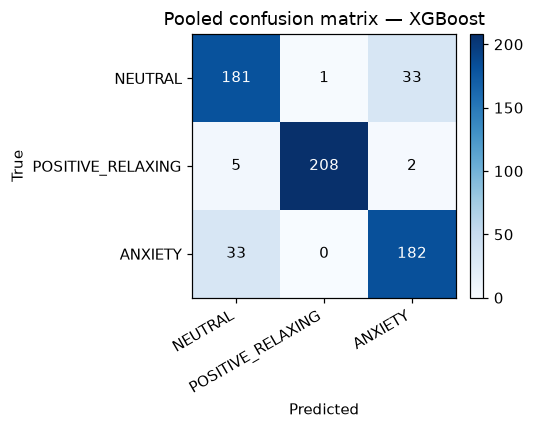

In [32]:

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Pooled confusion matrix — {best_model_name}")
for i in range(3):
    for j in range(3):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


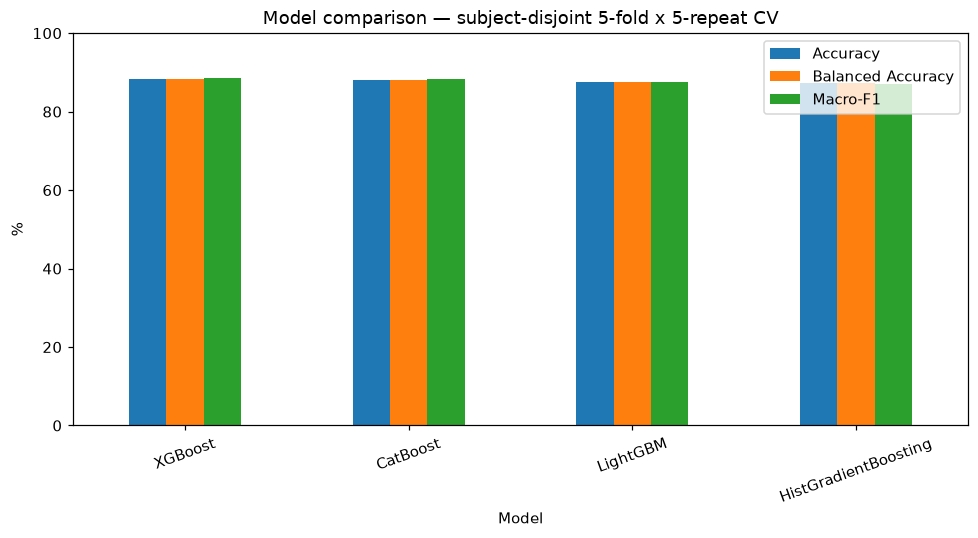

In [33]:

# Bar chart comparing all models
plot_df = result_table.set_index("Model")[["Accuracy", "Balanced Accuracy", "Macro-F1"]]
ax = plot_df.plot(kind="bar", figsize=(9, 5), rot=20)
ax.set_ylabel("%")
ax.set_ylim(0, 100)
ax.set_title("Model comparison — subject-disjoint 5-fold x 5-repeat CV")
plt.tight_layout()
plt.show()
